In [134]:
import pandas as pd
import numpy as np

In [135]:
df = pd.read_csv("sample_store.csv")

In [136]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [137]:
df.isnull().sum()

,0
Ship Mode,0
Segment,0
Country,0
City,0
State,0
Postal Code,0
Region,0
Category,0
Sub-Category,0
Sales,0


In [138]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB


In [139]:
df.count()

,0
Ship Mode,9994
Segment,9994
Country,9994
City,9994
State,9994
Postal Code,9994
Region,9994
Category,9994
Sub-Category,9994
Sales,9994


In [140]:
df.duplicated().sum()

np.int64(17)

In [141]:
df = df.drop_duplicates()

In [142]:
import matplotlib.pyplot as plt
import seaborn as sns

In [143]:
df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')

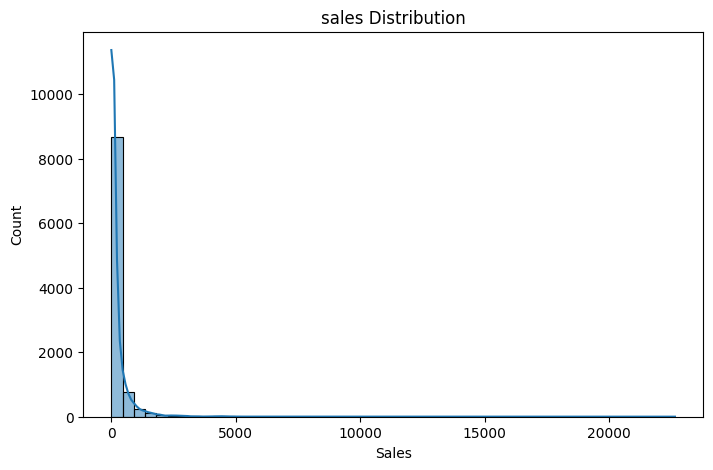

In [144]:
# Sales distribution

plt.figure(figsize =(8,5))
sns.histplot(df['Sales'],bins=50,kde=True)
plt.title("sales Distribution")
plt.show()

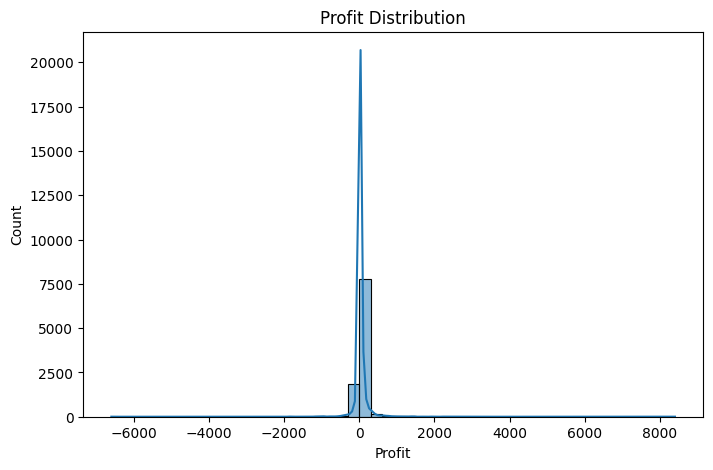

In [145]:
# profit distribution

plt.figure(figsize = (8,5))
sns.histplot(df["Profit"],bins=50,kde=True)
plt.title("Profit Distribution")
plt.show()

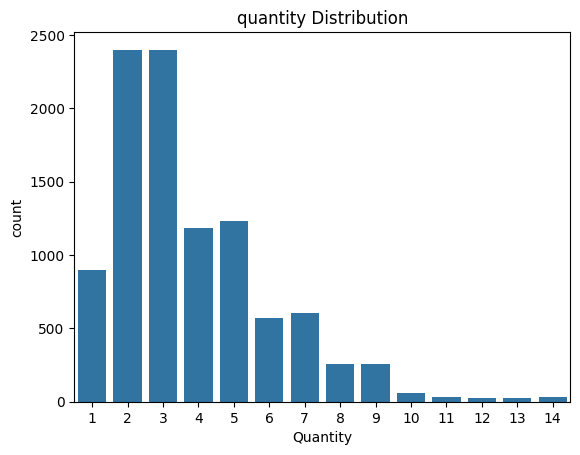

In [146]:
# Quantity distribution

sns.countplot(data=df,x="Quantity")
plt.title("quantity Distribution")
plt.show()

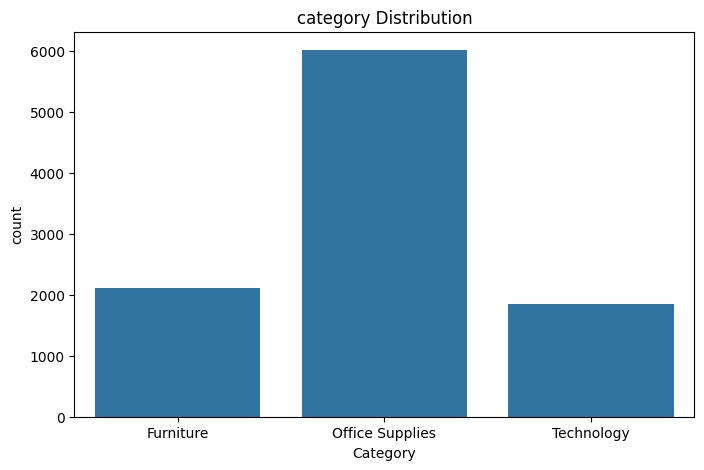

In [147]:
plt.figure(figsize=(8,5))
sns.countplot(data=df,x="Category")
plt.title("category Distribution")
plt.show()

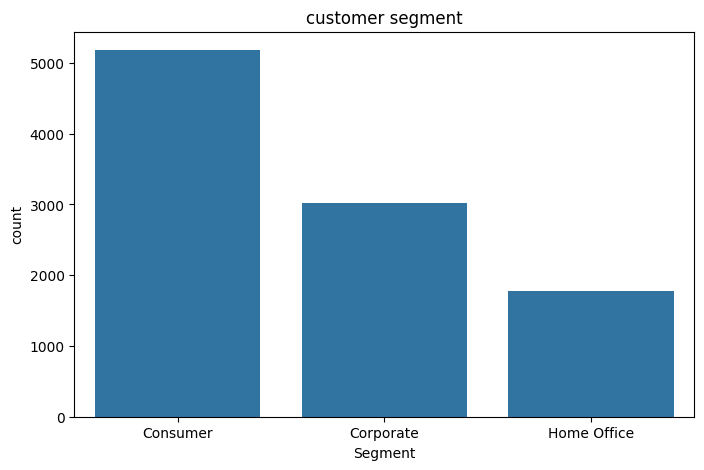

In [148]:
# segment count

plt.figure(figsize=(8,5))
sns.countplot(data=df,x="Segment")
plt.title("customer segment")
plt.show()

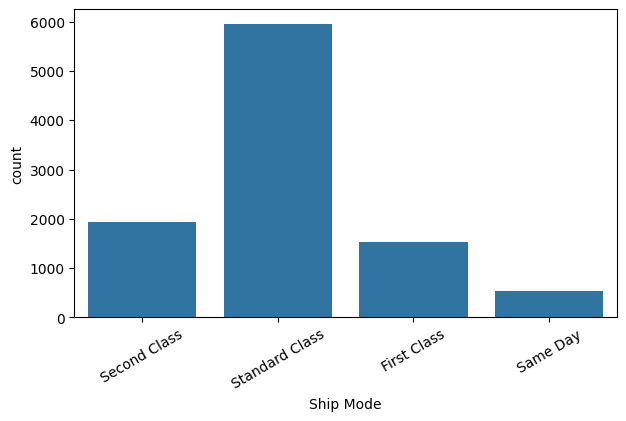

In [149]:
# Ship Mode
plt.figure(figsize=(7,4))
sns.countplot(data=df, x="Ship Mode")
plt.xticks(rotation=30)
plt.show()

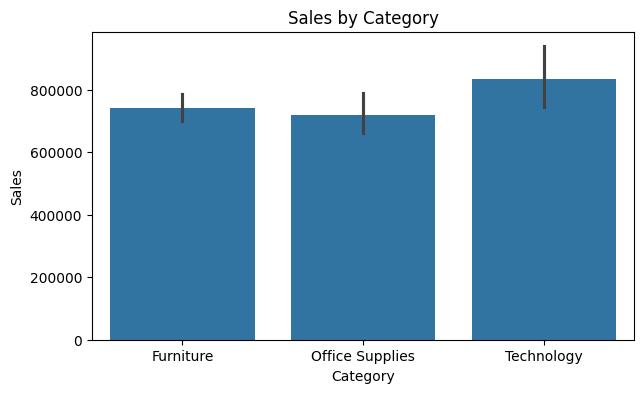

In [150]:
plt.figure(figsize=(7,4))
sns.barplot(data=df, x="Category",y="Sales",estimator="sum")
plt.title("Sales by Category")
plt.show()

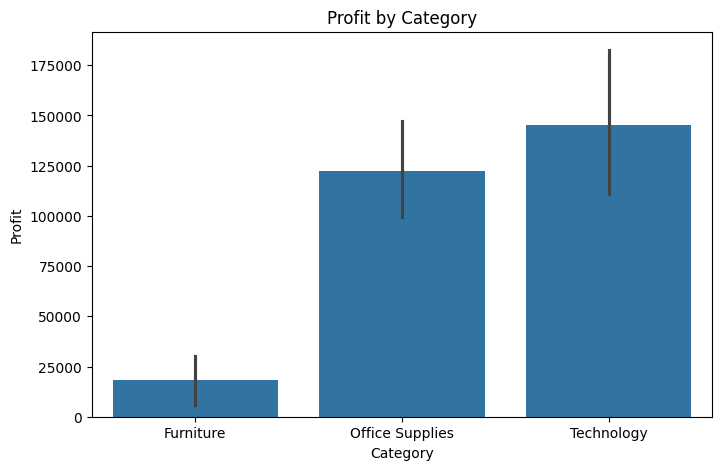

In [151]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="Category", y="Profit", estimator="sum")
plt.title("Profit by Category")
plt.show()

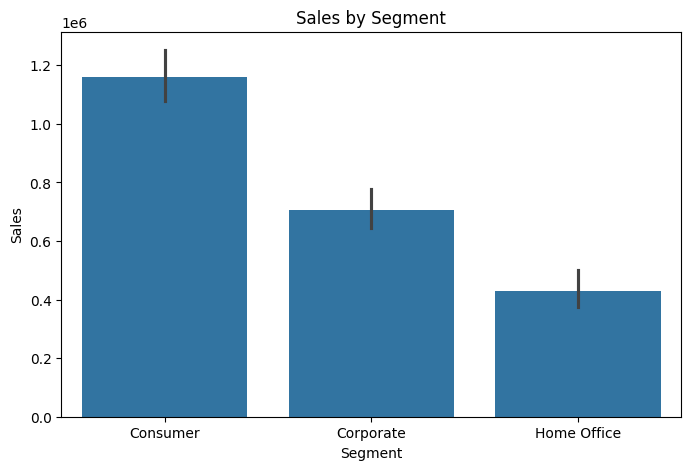

In [152]:
plt.figure(figsize=(8,5))
sns.barplot(data=df, x="Segment", y="Sales", estimator="sum")
plt.title("Sales by Segment")
plt.show()

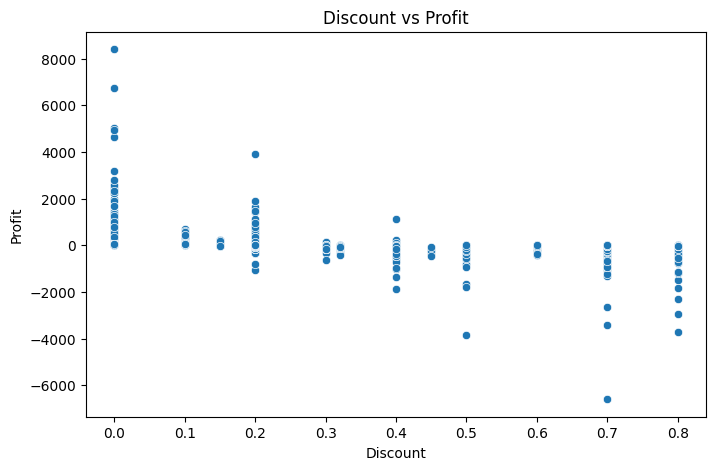

In [153]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Discount", y="Profit")
plt.title("Discount vs Profit")
plt.show()

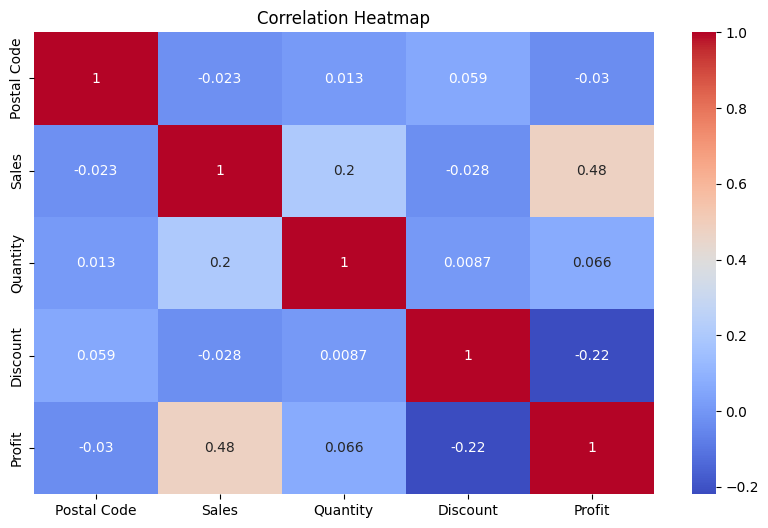

In [154]:
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

In [155]:
# Feature eng

df["Sales_per_Quantity"] = df["Sales"] / df["Quantity"]

# Profit margin
df["Profit_Margin"] = (df["Profit"] / df["Sales"]) * 100

# Is profitable?
df["Is_Profitable"] = (df["Profit"] > 0).astype(int)

# High discount
df["High_Discount"] = (df["Discount"] >= 0.20).astype(int)

df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit,Sales_per_Quantity,Profit_Margin,Is_Profitable,High_Discount
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,130.9800,16.00,1,0
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820,243.9800,30.00,1,0
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,7.3100,47.00,1,0
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310,191.5155,-40.00,0,1
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,11.1840,11.25,1,1


In [156]:
df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Sales_per_Quantity', 'Profit_Margin', 'Is_Profitable',
       'High_Discount'],
      dtype='object')

In [157]:
df["Discount_category"] = pd.cut(
    df["Discount"],
    bins = [-0.01,0,0.10,0.20,0.50,1],
    labels = ["No Discount","LOw","Medium","High","very High"]
)

In [158]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit,Sales_per_Quantity,Profit_Margin,Is_Profitable,High_Discount,Discount_category
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,130.9800,16.00,1,0,No Discount
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820,243.9800,30.00,1,0,No Discount
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,7.3100,47.00,1,0,No Discount
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310,191.5155,-40.00,0,1,High
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,11.1840,11.25,1,1,Medium


In [159]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9977 entries, 0 to 9993
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   Ship Mode           9977 non-null   object  
 1   Segment             9977 non-null   object  
 2   Country             9977 non-null   object  
 3   City                9977 non-null   object  
 4   State               9977 non-null   object  
 5   Postal Code         9977 non-null   int64   
 6   Region              9977 non-null   object  
 7   Category            9977 non-null   object  
 8   Sub-Category        9977 non-null   object  
 9   Sales               9977 non-null   float64 
 10  Quantity            9977 non-null   int64   
 11  Discount            9977 non-null   float64 
 12  Profit              9977 non-null   float64 
 13  Sales_per_Quantity  9977 non-null   float64 
 14  Profit_Margin       9977 non-null   float64 
 15  Is_Profitable       9977 non-null   int64  

In [160]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

df["Ship Mode"] = le.fit_transform(df["Ship Mode"])
df["Segment"] = le.fit_transform(df["Segment"])

df["Country"] = le.fit_transform(df["Country"])

df["City"] = le.fit_transform(df["City"])

df["State"] = le.fit_transform(df["State"])
df["Category"] = le.fit_transform(df["Category"])
df["Sub-Category"] = le.fit_transform(df["Sub-Category"])
df["Region"] = le.fit_transform(df["Region"])
df["Discount_category"] = le.fit_transform(df["Discount_category"])




In [161]:
df['Segment'].unique()

array([0, 1, 2])

In [162]:
df.head()

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit,Sales_per_Quantity,Profit_Margin,Is_Profitable,High_Discount,Discount_category
0,2,0,0,194,15,42420,2,0,4,261.9600,2,0.00,41.9136,130.9800,16.00,1,0,3
1,2,0,0,194,15,42420,2,0,5,731.9400,3,0.00,219.5820,243.9800,30.00,1,0,3
2,2,1,0,266,3,90036,3,1,10,14.6200,2,0.00,6.8714,7.3100,47.00,1,0,3
3,3,0,0,153,8,33311,2,0,16,957.5775,5,0.45,-383.0310,191.5155,-40.00,0,1,0
4,3,0,0,153,8,33311,2,1,14,22.3680,2,0.20,2.5164,11.1840,11.25,1,1,2


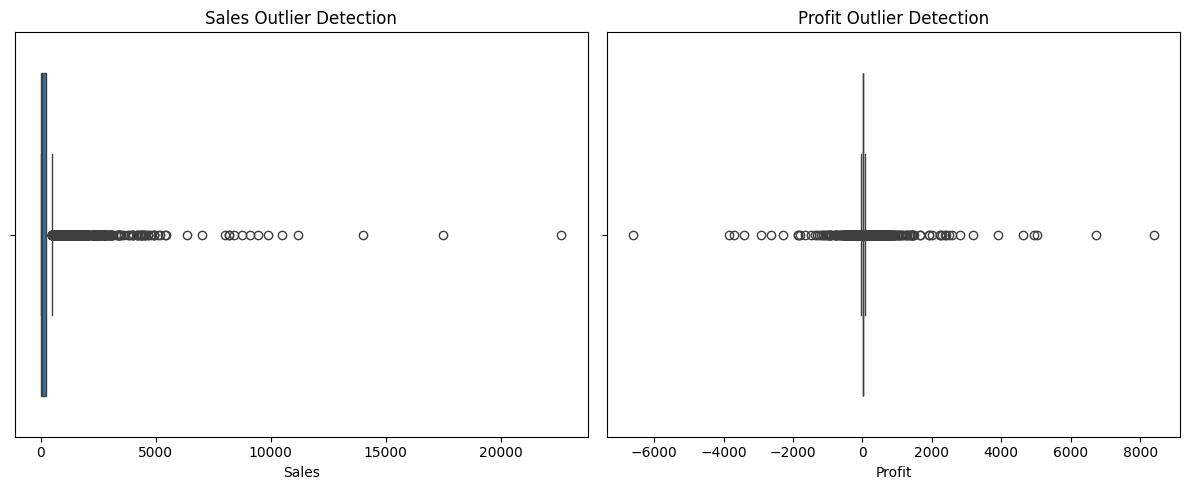

In [163]:
plt.figure(figsize=(12, 5))

# Sales Boxplot
plt.subplot(1, 2, 1)
sns.boxplot(x=df["Sales"])
plt.title("Sales Outlier Detection")

# Profit Boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=df["Profit"])
plt.title("Profit Outlier Detection")

plt.tight_layout()

plt.show()

In [164]:
for col in ["Sales" , "Profit"]:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) | (df[col] > upper_bound)
    ]

    print(col, "Outliers:", len(outliers))
    print("Percentage:", round(len(outliers)/len(df)*100, 2), "%")

Sales Outliers: 1167
Percentage: 11.7 %
Profit Outliers: 1881
Percentage: 18.85 %


In [165]:
Q1 = df["Profit"].quantile(0.25)
Q3 = df["Profit"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

profit_outliers = df[
    (df["Profit"] < lower) |
    (df["Profit"] > upper)
]

# Sub-category wise outliers
result = (
    profit_outliers.groupby("Sub-Category")
    .size()
    .sort_values(ascending=False)
)

print(result)

Sub-Category
13    264
5     225
3     209
16    208
0     160
14    156
1     137
12    122
9     100
4      94
11     82
6      63
7      28
15     13
10     11
2       9
dtype: int64


In [166]:
df.columns

Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit', 'Sales_per_Quantity', 'Profit_Margin', 'Is_Profitable',
       'High_Discount', 'Discount_category'],
      dtype='object')

In [167]:
x = df.drop(["City","City","Region","Category","Sub-Category","Quantity","Discount"],axis=1)

y = df["Sales"]

In [168]:
y.head()

,Sales
0,261.9600
1,731.9400
2,14.6200
3,957.5775
4,22.3680


In [169]:
# split out data
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [170]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.fit_transform(x_test)

In [171]:
x_train_scaled

array([[ 0.69428742, -0.86348451,  0.        , ...,  0.49329513,
         0.98076385, -0.61013524],
       [ 0.69428742,  0.44717921,  0.        , ...,  0.49329513,
         0.98076385, -0.61013524],
       [-2.03308317, -0.86348451,  0.        , ...,  0.49329513,
        -1.01961343,  0.53293738],
       ...,
       [-0.21483611,  0.44717921,  0.        , ...,  0.49329513,
        -1.01961343,  0.53293738],
       [ 0.69428742, -0.86348451,  0.        , ...,  0.49329513,
        -1.01961343,  0.53293738],
       [-1.12395964,  0.44717921,  0.        , ...,  0.49329513,
         0.98076385, -0.61013524]], shape=(7981, 12))

In [172]:
x_test_scaled

array([[ 0.69915561, -0.86620243,  0.        , ...,  0.47860635,
        -0.97819361,  0.53667557],
       [-2.01409377, -0.86620243,  0.        , ...,  0.47860635,
         1.02229251, -0.62138328],
       [ 0.69915561,  0.44858088,  0.        , ..., -2.08939977,
         1.02229251,  1.69473441],
       ...,
       [ 0.69915561,  0.44858088,  0.        , ...,  0.47860635,
         1.02229251, -0.62138328],
       [ 0.69915561, -0.86620243,  0.        , ...,  0.47860635,
        -0.97819361,  0.53667557],
       [ 0.69915561,  0.44858088,  0.        , ...,  0.47860635,
        -0.97819361,  0.53667557]], shape=(1996, 12))

In [173]:
import torch
import torch.nn as nn

x_train_tensor = torch.tensor(x_train_scaled,dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)

x_test_tensor = torch.tensor(x_test_scaled,dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)



In [174]:
type(x_train_tensor)

torch.Tensor

In [175]:
type(y_train)

pandas.core.series.Series

In [176]:
y_train.shape

(7981,)

In [177]:
from torch.utils.data import TensorDataset,DataLoader

train_dataset = TensorDataset(x_train_tensor,y_train_tensor)
test_dataset = TensorDataset(x_test_tensor,y_test_tensor)

train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader = DataLoader(test_dataset,batch_size=32,shuffle=False)

In [178]:
# Deep learning

# defiing the ann model



In [179]:
class ANN_Optimized(nn.Module):
    def __init__(self):
        super().__init__()

        self.model = nn.Sequential(

            nn.Linear(x_train.shape[1], 32),
            nn.ReLU(),

            nn.Linear(32, 16),
            nn.ReLU(),

            nn.Linear(16, 8),
            nn.ReLU(),

            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.model(x)

In [180]:
model = ANN_Optimized()

criterion = nn.MSELoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

In [181]:

# Train the ANN

train_losses = []
val_losses = []

best_val_loss = float("inf")

patience = 10
counter = 0
epochs = 100

for epoch in range(epochs):

    # ---------------- TRAINING ----------------
    model.train()

    running_loss = 0.0

    for xb, yb in train_loader:

        optimizer.zero_grad()

        outputs = model(xb)

        loss = criterion(outputs, yb)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_train_loss = running_loss / len(train_loader)

    train_losses.append(epoch_train_loss)

    # ---------------- VALIDATION ----------------
    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for xb, yb in test_loader:

            outputs = model(xb)

            loss = criterion(outputs, yb)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(test_loader)

    val_losses.append(epoch_val_loss)

    print(
        f"Epoch {epoch+1}/{epochs} "
        f"Train Loss: {epoch_train_loss:.4f} "
        f"Val Loss: {epoch_val_loss:.4f}"
    )

    # ---------------- EARLY STOPPING ----------------

    if epoch_val_loss < best_val_loss:

        best_val_loss = epoch_val_loss

        counter = 0

        torch.save(model.state_dict(), "best_model.pt")

    else:

        counter += 1

    if counter >= patience:

        print("Early Stopping Triggered!")

        break

# ---------------- LOAD BEST MODEL ----------------

model.load_state_dict(
    torch.load("best_model.pt", weights_only=True)
)

print("Best Model Loaded Successfully!")
print("Best Validation Loss:", best_val_loss)


Epoch 1/100 Train Loss: 445209.6806 Val Loss: 389945.4361
Epoch 2/100 Train Loss: 373330.5304 Val Loss: 261681.3618
Epoch 3/100 Train Loss: 196262.3407 Val Loss: 114578.4632
Epoch 4/100 Train Loss: 86166.0816 Val Loss: 49120.0412
Epoch 5/100 Train Loss: 45485.0682 Val Loss: 32852.4578
Epoch 6/100 Train Loss: 34994.9004 Val Loss: 27354.4236
Epoch 7/100 Train Loss: 29898.9181 Val Loss: 23552.6058
Epoch 8/100 Train Loss: 26203.1825 Val Loss: 21394.7160
Epoch 9/100 Train Loss: 23367.2056 Val Loss: 17695.9566
Epoch 10/100 Train Loss: 20583.0052 Val Loss: 16303.5409
Epoch 11/100 Train Loss: 18427.2634 Val Loss: 13775.9304
Epoch 12/100 Train Loss: 16457.9113 Val Loss: 12134.1890
Epoch 13/100 Train Loss: 14137.0027 Val Loss: 11018.8725
Epoch 14/100 Train Loss: 12822.6909 Val Loss: 9084.5389
Epoch 15/100 Train Loss: 11478.2865 Val Loss: 8572.3894
Epoch 16/100 Train Loss: 9988.5884 Val Loss: 7742.4565
Epoch 17/100 Train Loss: 8781.9235 Val Loss: 7285.5575
Epoch 18/100 Train Loss: 7483.0903 Val L

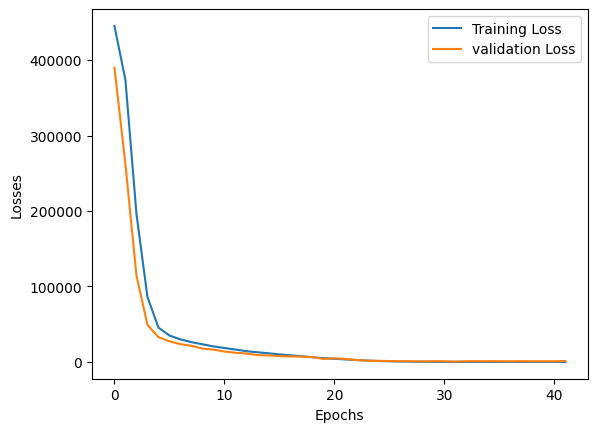

In [182]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss":train_losses,
    "validation Loss":val_losses

})

plt.plot(loss_df["Training Loss"],label = "Training Loss")
plt.plot(loss_df["validation Loss"],label = "validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

In [183]:
# Loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [184]:
# Evaluation

model.eval()
with torch.no_grad():
    train_preds = model(x_train_tensor)
    test_preds = model(x_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 184.11790466308594
Testing MSE: 441.4747314453125


In [185]:
from sklearn.metrics import r2_score

print("r^2 score= ",r2_score(y_test,test_preds))

r^2 score=  0.998770378301256


In [186]:
predicted_df = pd.DataFrame(
    test_preds.detach().cpu().numpy(),
    columns=["Predicted values"]
)

actual_df = pd.DataFrame(
    y_test_tensor.detach().cpu().numpy(),
    columns=["Actual values"]
)

results = pd.concat(
    [predicted_df, actual_df],
    axis=1
)

print(results)

      Predicted values  Actual values
0            20.117882      29.980000
1            46.165241      53.248001
2             9.786572      16.146000
3            20.512432      27.992001
4           560.806152     558.400024
...                ...            ...
1991         32.142231       5.768000
1992        772.577942     760.116028
1993        156.055069     170.352005
1994         31.235802      39.980000
1995        230.344467     239.699997

[1996 rows x 2 columns]


In [187]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import numpy as np

y_pred = test_preds.detach().cpu().numpy().flatten()

y_actual = y_test_tensor.detach().cpu().numpy().flatten()

mae = mean_absolute_error(y_actual, y_pred)

mse = mean_squared_error(y_actual, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_actual, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 9.466018676757812
MSE: 441.4747009277344
RMSE: 21.011299363145877
R2 Score: 0.9987703561782837


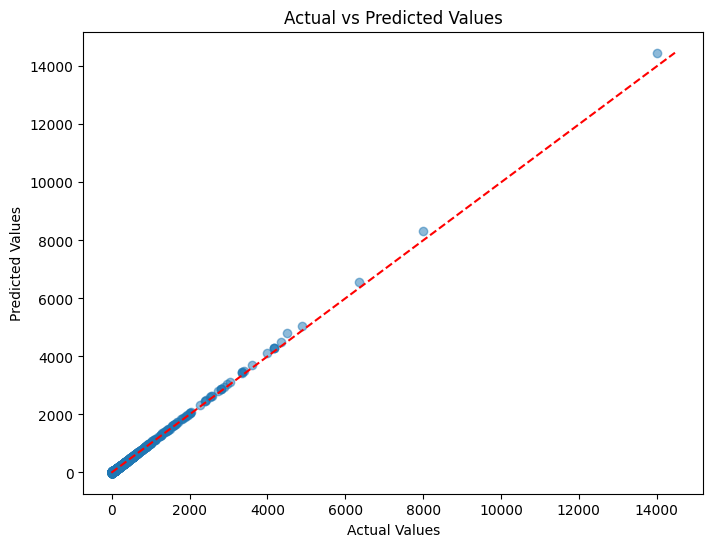

In [188]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_actual, y_pred, alpha=0.5)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted Values")

# Perfect prediction reference line
min_val = min(y_actual.min(), y_pred.min())
max_val = max(y_actual.max(), y_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    'r--'
)

plt.show()

In [189]:
results["Error"] = (
    results["Actual Values"] -
    results["Predicted values"]
)

results["Absolute Error"] = abs(results["Error"])

# Top 10 worst predictions
print(
    results.sort_values(
        by="Absolute Error",
        ascending=False
    ).head(10)
)

      Predicted values  Actual values       Error  Absolute Error
168       14469.789062   13999.959961 -469.829102      469.829102
907        4824.355469    4499.984863 -324.370605      324.370605
898        8307.643555    7999.979980 -307.663574      307.663574
1307       6555.590820    6354.950195 -200.640625      200.640625
854        5046.218750    4899.930176 -146.288574      146.288574
906        4131.921387    3991.979980 -139.941406      139.941406
1054       4297.003418    4164.049805 -132.953613      132.953613
986        4296.072754    4164.049805 -132.022949      132.022949
1211       4486.685059    4355.167969 -131.517090      131.517090
976        4275.787109    4158.912109 -116.875000      116.875000


In [195]:
import torch
import joblib

torch.save(model.state_dict(),"best_model.pth")

joblib.dump(scaler,"scaler.pkl")

joblib.dump(x_train.columns.tolist(),"feature_columns.pkl")

['feature_columns.pkl']

In [196]:
import os
import zipfile

files_to_zip = [
    "best_model.pth",
    "scaler.pkl",
    "feature_columns.pkl"
]

with zipfile.ZipFile("Sales_Prediction_Model.zip", "w") as zipf:
    for file in files_to_zip:
        zipf.write(file)

from google.colab import files

files.download("Sales_Prediction_Model.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>